In [1]:
# Import Required Libraries

import warnings
warnings.filterwarnings("ignore")

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Feature Selection
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
chronic_kidney_disease = fetch_ucirepo(id=336)

# data (as pandas dataframes)
X = chronic_kidney_disease.data.features
y = chronic_kidney_disease.data.targets

# metadata
print(chronic_kidney_disease.metadata)

# variable information
print(chronic_kidney_disease.variables)

{'uci_id': 336, 'name': 'Chronic Kidney Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/336/data.csv', 'abstract': 'This dataset can be used to predict the chronic kidney disease and it can be collected from the hospital nearly 2 months of period.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 400, 'num_features': 24, 'feature_types': ['Real'], 'demographics': ['Age'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5G020', 'creators': ['L. Rubini', 'P. Soundarapandian', 'P. Eswaran'], 'intro_paper': None, 'additional_info': {'summary': 'We use the following representation to collect the dataset\r\n                        age\t\t-\tage\t\r\n\t\t\tbp\t\t-\tblood pressure\r\n\t\t\tsg\t

In [4]:
df = pd.concat([X, y], axis=1)

print("Rows and Columns:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Rows and Columns:
(400, 25)

First 5 Rows:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-n

In [5]:
print("Number of Rows :", df.shape[0])
print("Number of Columns :", df.shape[1])

Number of Rows : 400
Number of Columns : 25


# Removing Duplicate Records (If Any)

In [6]:
duplicates = df.duplicated().sum()

print("Duplicate Records :", duplicates)

df = df.drop_duplicates()

print("New Shape :", df.shape)

Duplicate Records : 0
New Shape : (400, 25)


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, trends, and distributions within the dataset before preprocessing and model development.

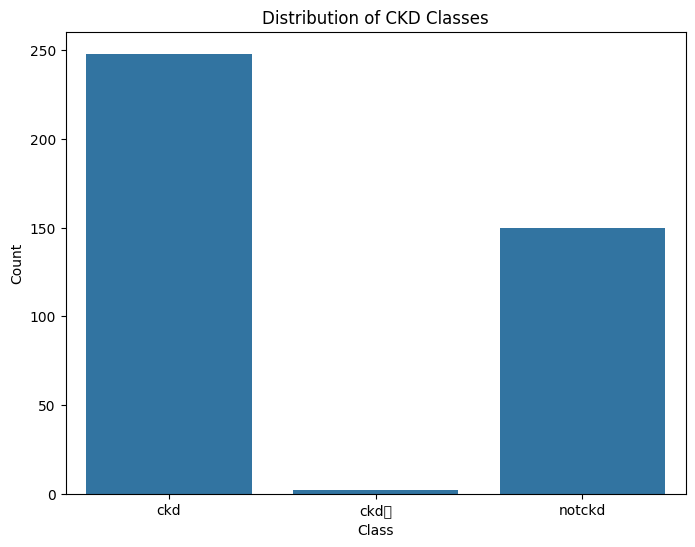

In [8]:
plt.figure(figsize=(8,6))

sns.countplot(x='class', data=df)

plt.title("Distribution of CKD Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

# Numerical Feature Distribution

Histograms help visualize the distribution of numerical variables and identify skewness or unusual patterns.

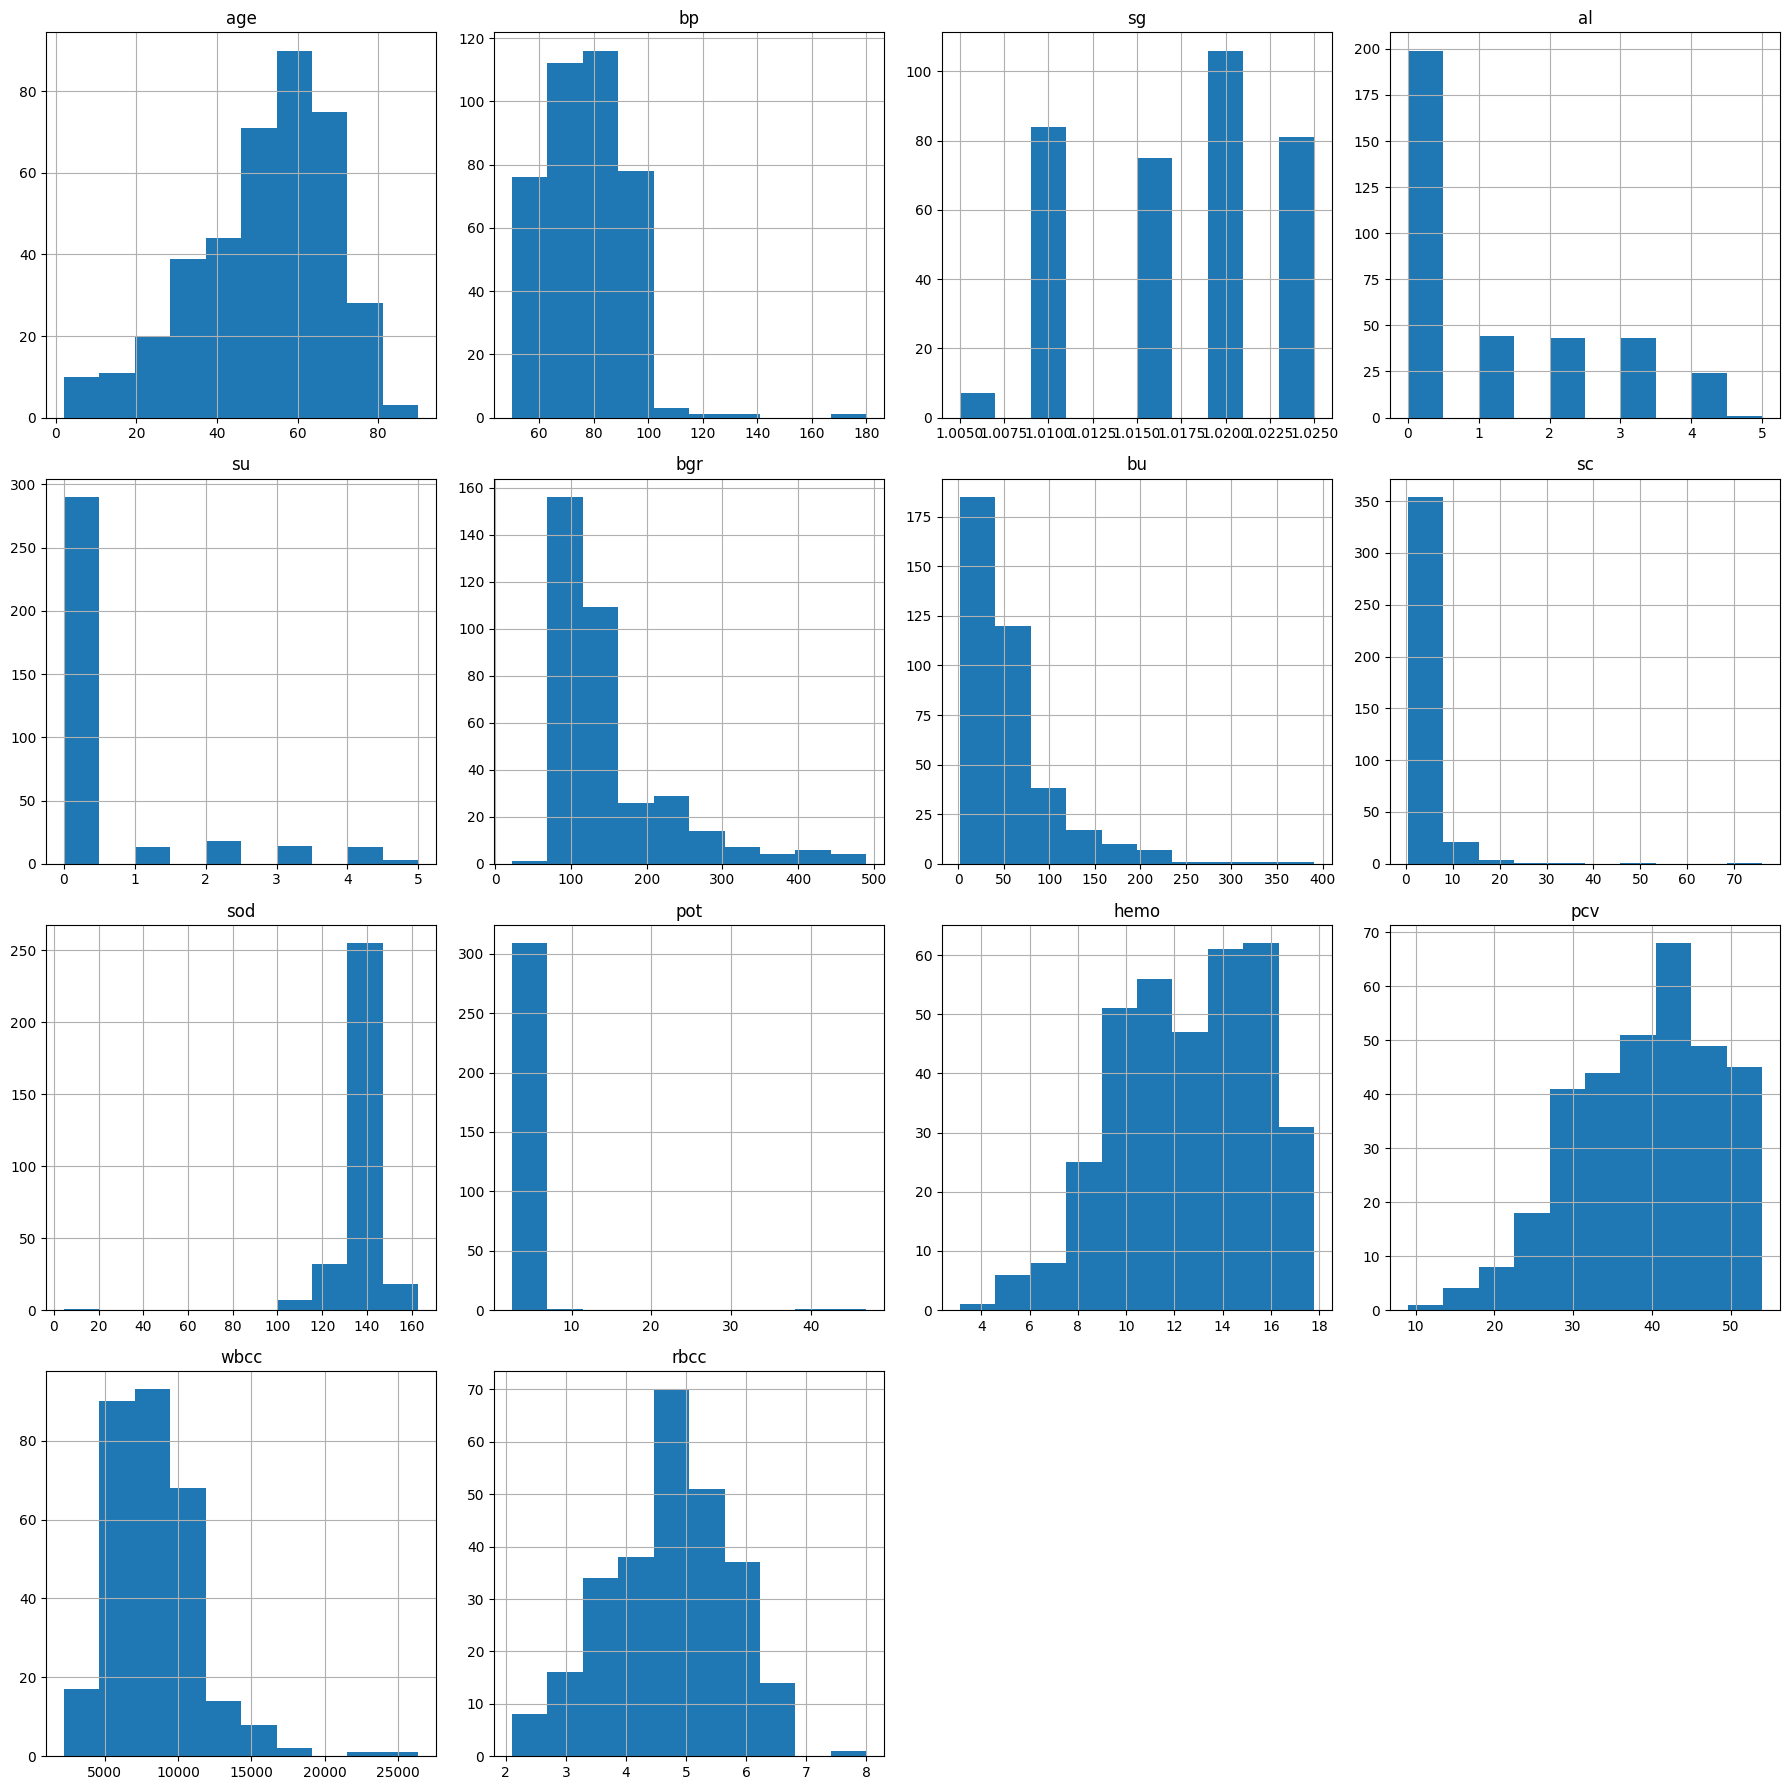

In [9]:
df.hist(figsize=(18,18))

plt.tight_layout()

plt.show()

# Correlation Heatmap (Initial)

A heatmap helps identify relationships among numerical features. Strong correlations can assist in feature engineering and feature selection later in the project.

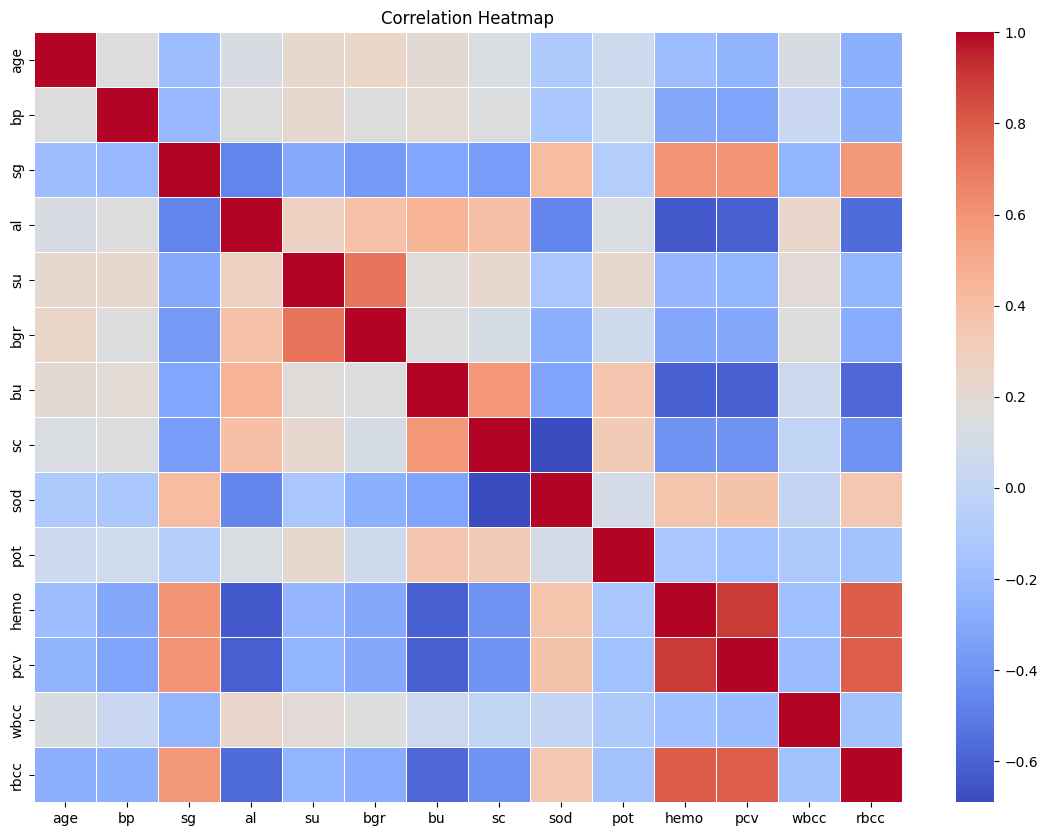

In [10]:
plt.figure(figsize=(14,10))

sns.heatmap(df.corr(numeric_only=True),
            cmap='coolwarm',
            linewidths=0.5)

plt.title("Correlation Heatmap")

plt.show()

# Pairwise Relationships

Scatter plots provide insight into relationships between selected numerical variables.

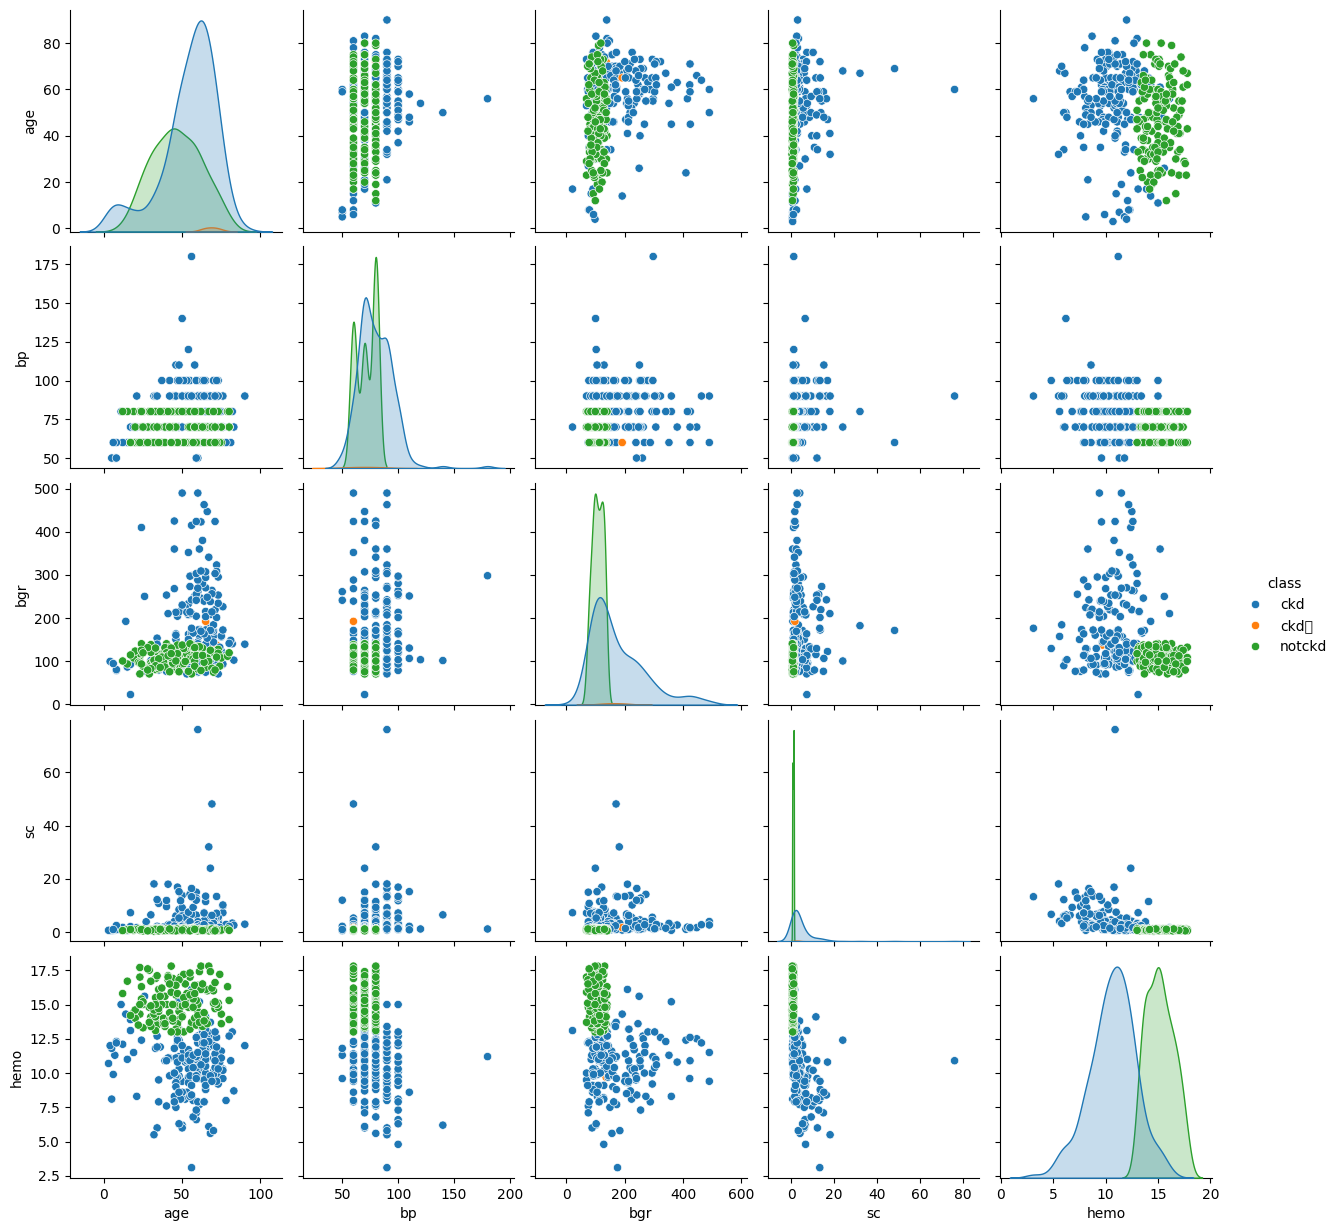

In [13]:
sns.pairplot(
    df[['age','bp','bgr','sc','hemo','class']],
    hue='class'
)

plt.show()

In [14]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values.sort_values(ascending=False)

,0
rbc,152
rbcc,131
wbcc,106
pot,88
sod,87
pcv,71
pc,65
hemo,52
su,49
sg,47


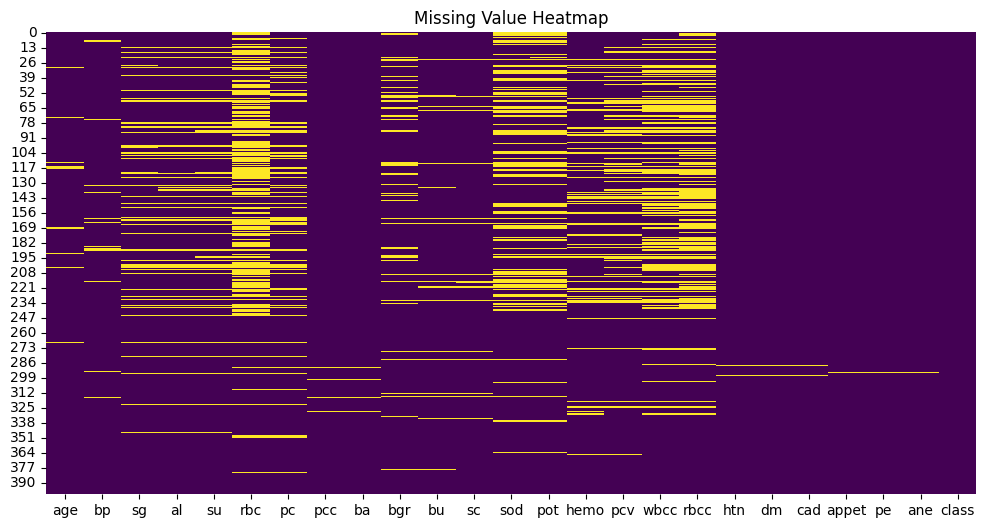

In [15]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis")

plt.title("Missing Value Heatmap")

plt.show()

# Separating Numerical and Categorical Columns

In [16]:
numerical_columns = df.select_dtypes(include=['int64','float64']).columns

categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical Columns")

print(numerical_columns)

print("\nCategorical Columns")

print(categorical_columns)

Numerical Columns
Index(['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo',
       'pcv', 'wbcc', 'rbcc'],
      dtype='object')

Categorical Columns
Index(['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane',
       'class'],
      dtype='object')


# Handling Missing Values

In [17]:
# Numerical Imputation

num_imputer = SimpleImputer(strategy="median")

df[numerical_columns] = num_imputer.fit_transform(df[numerical_columns])

In [18]:
# Categorical Imputation

cat_imputer = SimpleImputer(strategy="most_frequent")

df[categorical_columns] = cat_imputer.fit_transform(df[categorical_columns])

In [19]:
# Verify Missing Values

df.isnull().sum()

,0
age,0
bp,0
sg,0
al,0
su,0
rbc,0
pc,0
pcc,0
ba,0
bgr,0


In [20]:
encoder = LabelEncoder()

for col in categorical_columns:

    df[col] = encoder.fit_transform(df[col])

print("Categorical Features Encoded Successfully")

Categorical Features Encoded Successfully


In [23]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,2,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.8,0,1,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.8,0,2,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,1,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,1,0,0,0,0,0


# Data Type Verification

After encoding, all columns should now contain numerical values suitable for machine learning algorithms.

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     400 non-null    float64
 1   bp      400 non-null    float64
 2   sg      400 non-null    float64
 3   al      400 non-null    float64
 4   su      400 non-null    float64
 5   rbc     400 non-null    int64  
 6   pc      400 non-null    int64  
 7   pcc     400 non-null    int64  
 8   ba      400 non-null    int64  
 9   bgr     400 non-null    float64
 10  bu      400 non-null    float64
 11  sc      400 non-null    float64
 12  sod     400 non-null    float64
 13  pot     400 non-null    float64
 14  hemo    400 non-null    float64
 15  pcv     400 non-null    float64
 16  wbcc    400 non-null    float64
 17  rbcc    400 non-null    float64
 18  htn     400 non-null    int64  
 19  dm      400 non-null    int64  
 20  cad     400 non-null    int64  
 21  appet   400 non-null    int64  
 22  pe

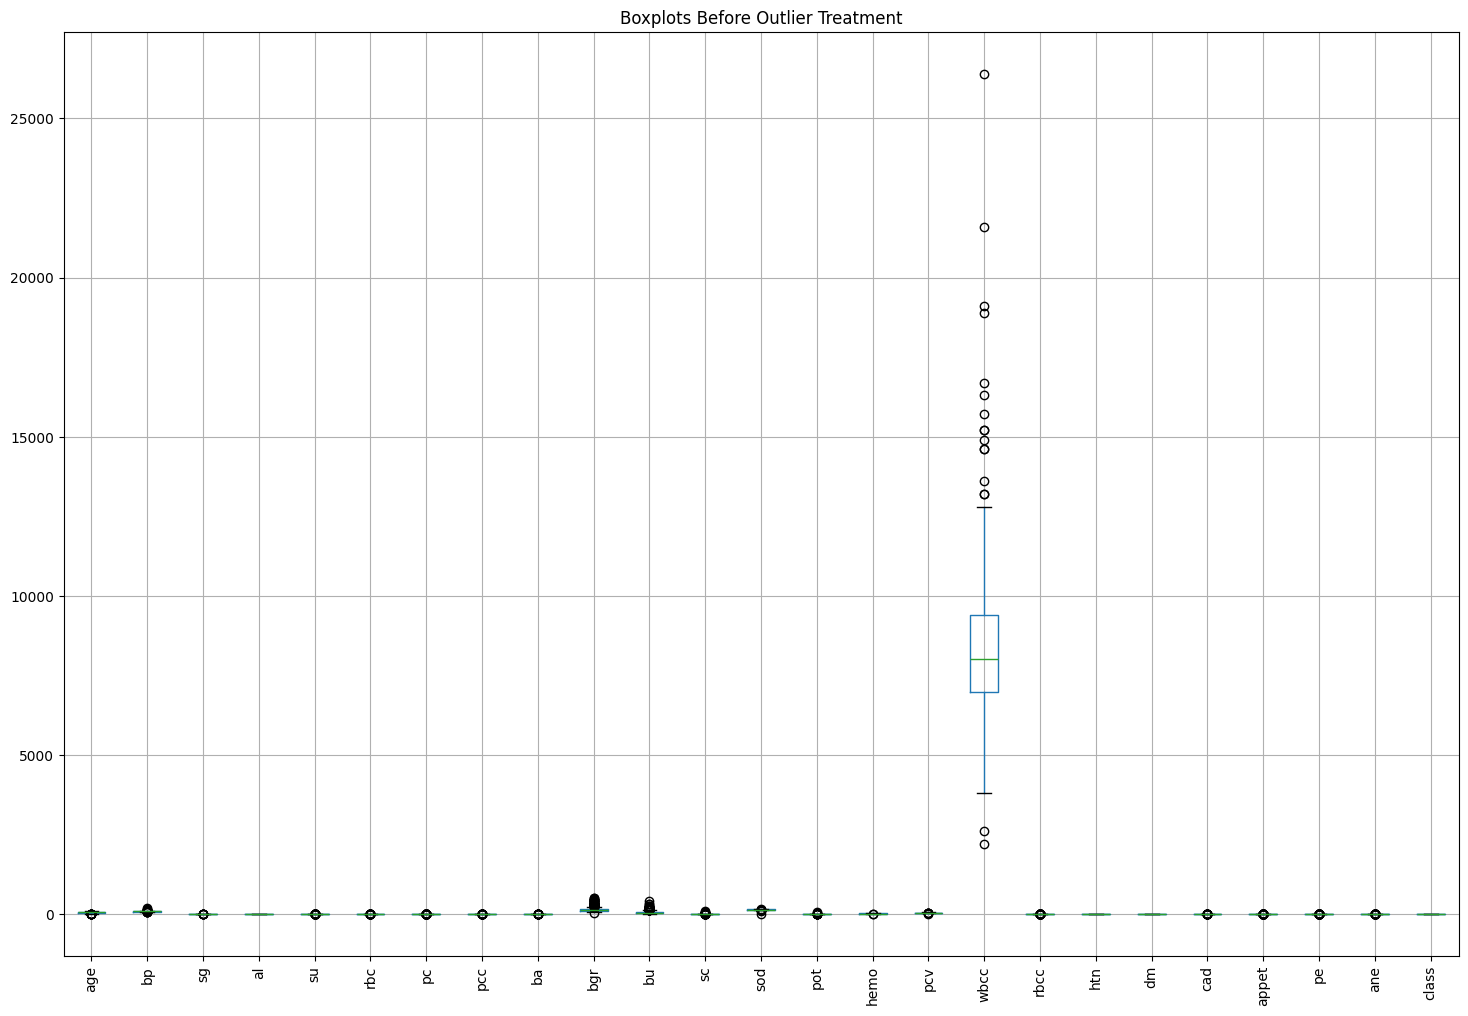

In [26]:
#outlier detection
plt.figure(figsize=(18,12))

df.boxplot(rot=90)

plt.title("Boxplots Before Outlier Treatment")

plt.show()

In [27]:
# hadling outlier
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:

    if col != "classification":

        Q1 = df[col].quantile(0.25)

        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR

        upper = Q3 + 1.5 * IQR

        df[col] = df[col].clip(lower, upper)

print("Outlier Treatment Completed")

Outlier Treatment Completed


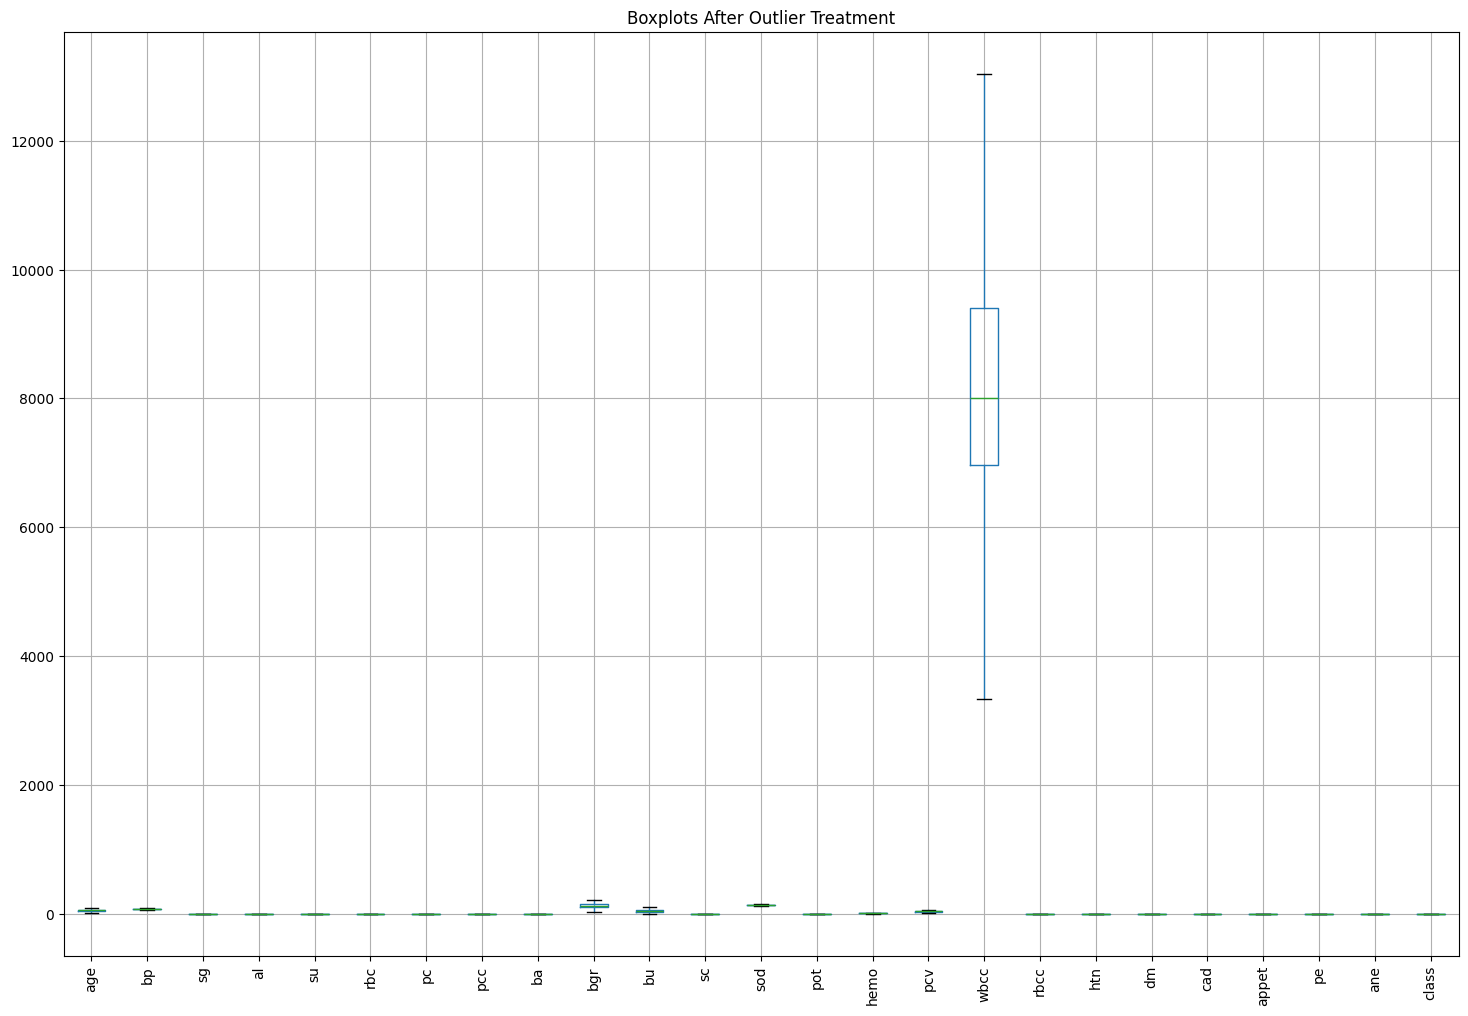

In [28]:
plt.figure(figsize=(18,12))

df.boxplot(rot=90)

plt.title("Boxplots After Outlier Treatment")

plt.show()

# Feature Scaling

In [30]:
X = df.drop("class", axis=1)

y = df["class"]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane
0,-0.217955,0.381013,0.420662,0.076249,0.0,0.0,0.0,0.0,0.0,-0.282640,...,1.058546,0.609001,-0.181983,0.638364,1.311903,1.377994,0.0,0.0,0.0,0.0
1,-2.548388,-1.900504,0.420662,2.363728,0.0,0.0,0.0,0.0,0.0,-0.282640,...,-0.463740,-0.143626,-1.069478,0.044882,-0.762252,-0.709876,0.0,0.0,0.0,0.0
2,0.618610,0.381013,-1.454156,0.838742,0.0,0.0,0.0,0.0,0.0,1.943938,...,-1.094932,-1.021691,-0.329898,0.044882,-0.762252,1.377994,0.0,0.0,0.0,0.0
3,-0.217955,-0.531594,-1.922860,2.363728,0.0,0.0,0.0,0.0,0.0,-0.369530,...,-0.500869,-0.896254,-0.724341,-1.290453,1.311903,-0.709876,0.0,0.0,0.0,0.0
4,-0.038691,0.381013,-1.454156,0.838742,0.0,0.0,0.0,0.0,0.0,-0.608480,...,-0.352353,-0.519940,-0.428509,-0.251859,-0.762252,-0.709876,0.0,0.0,0.0,0.0


In [31]:
# scaling verification

X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
age,400.0,-5.329071e-17,1.001252,-2.548388,-0.576483,0.200328,0.738120,2.291741
bp,400.0,-2.664535e-16,1.001252,-1.900504,-0.531594,0.381013,0.381013,1.749924
sg,400.0,9.663381e-15,1.001252,-1.922860,-0.516747,0.420662,0.420662,1.358071
al,400.0,3.552714e-17,1.001252,-0.686244,-0.686244,-0.686244,0.838742,3.126221
su,400.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
rbc,400.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pc,400.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pcc,400.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ba,400.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
bgr,400.0,2.131628e-16,1.001252,-2.313713,-0.717094,-0.282640,0.347319,1.943938


In [32]:

# FEATURE ENGINEERING

# Create copies of important categorical variables
# as binary numerical features

binary_columns = [
    'htn',
    'dm',
    'cad',
    'ane',
    'pe',
    'ba'
]

for col in binary_columns:

    if col in df.columns:

        df[col + "_num"] = df[col]

print("Feature Engineering Completed")

print()

print("New Dataset Shape:")

print(df.shape)

print()

print(df.head())

Feature Engineering Completed

New Dataset Shape:
(400, 31)

    age    bp      sg   al   su  rbc  pc  pcc  ba    bgr  ...  appet  pe  ane  \
0  48.0  80.0  1.0200  1.0  0.0    1   1    0   0  121.0  ...      0   0    0   
1   9.0  55.0  1.0200  4.0  0.0    1   1    0   0  121.0  ...      0   0    0   
2  62.0  80.0  1.0100  2.0  0.0    1   1    0   0  223.5  ...      0   0    0   
3  48.0  70.0  1.0075  4.0  0.0    1   1    0   0  117.0  ...      0   0    0   
4  51.0  80.0  1.0100  2.0  0.0    1   1    0   0  106.0  ...      0   0    0   

   class  htn_num  dm_num  cad_num  ane_num  pe_num  ba_num  
0      0        1       2        0        0       0       0  
1      0        0       1        0        0       0       0  
2      0        0       2        0        0       0       0  
3      0        1       1        0        0       0       0  
4      0        0       1        0        0       0       0  

[5 rows x 31 columns]


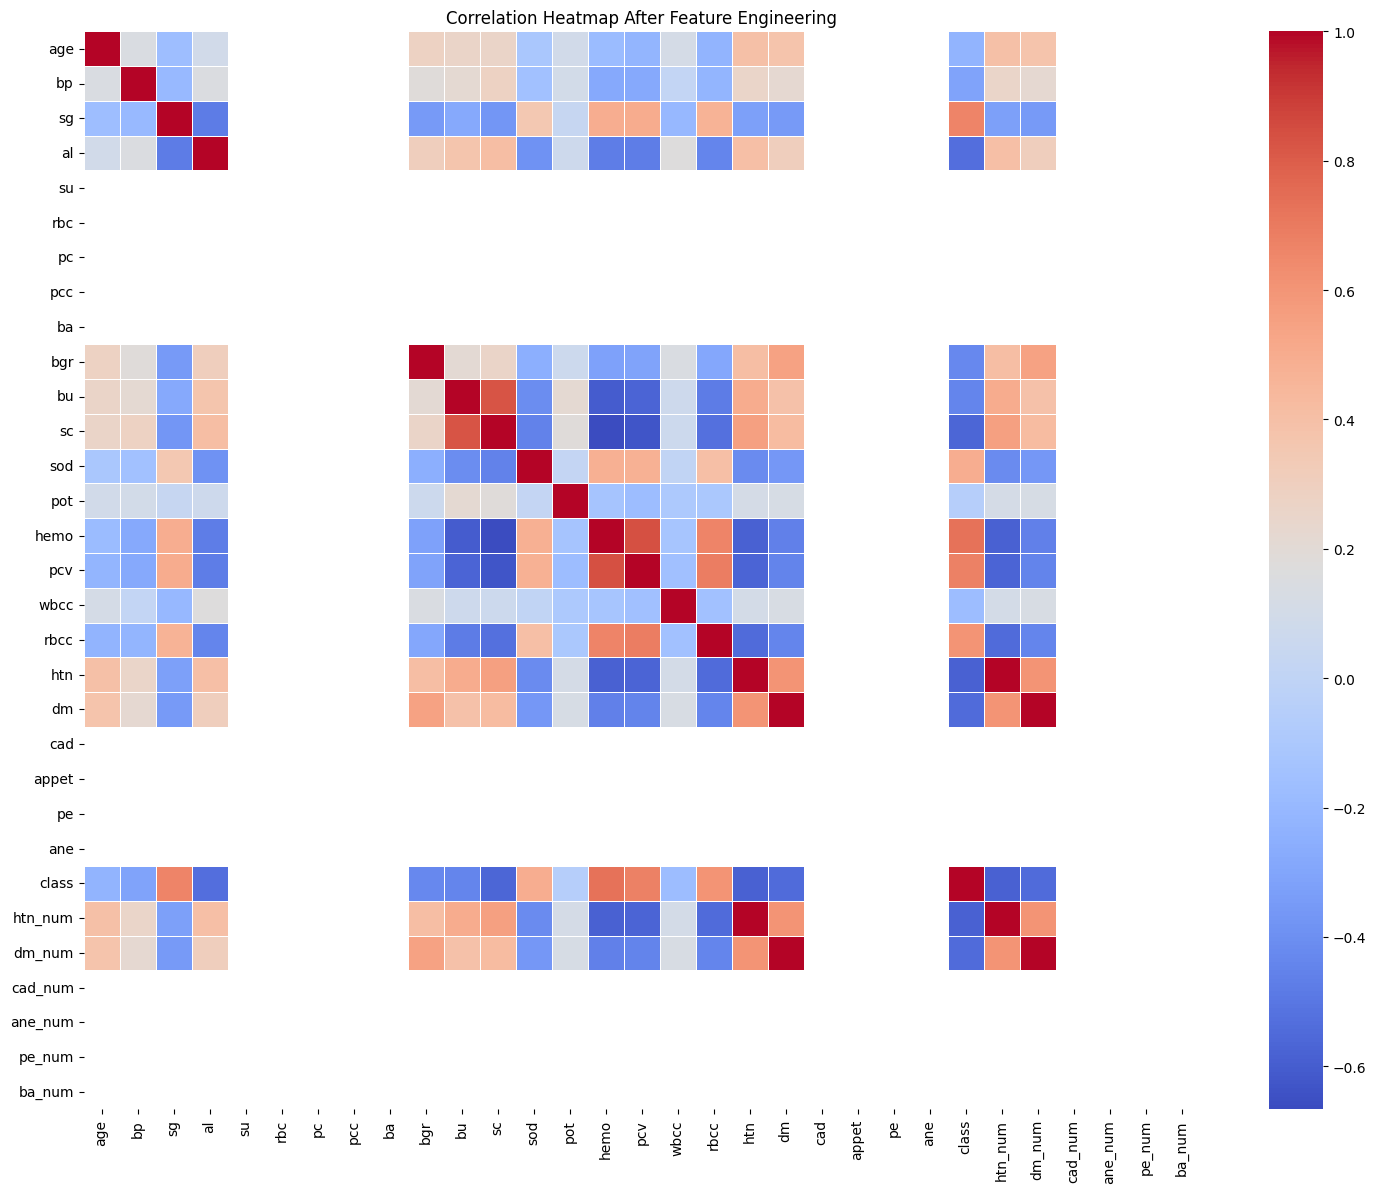

class      1.000000
hemo       0.728178
pcv        0.679835
sg         0.662922
rbcc       0.608922
sod        0.496446
pot       -0.051305
wbcc      -0.171924
age       -0.229971
bp        -0.311256
bgr       -0.430572
bu        -0.440388
al        -0.531885
dm_num    -0.543484
dm        -0.543484
sc        -0.564289
htn       -0.584451
htn_num   -0.584451
su              NaN
rbc             NaN
pc              NaN
pcc             NaN
ba              NaN
cad             NaN
appet           NaN
pe              NaN
ane             NaN
cad_num         NaN
ane_num         NaN
pe_num          NaN
ba_num          NaN
Name: class, dtype: float64


In [34]:

# CORRELATION ANALYSIS

plt.figure(figsize=(18,14))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap After Feature Engineering")

plt.show()

# display strongest correlations with target variable

target_corr = correlation_matrix["class"].sort_values(ascending=False)

print(target_corr)

In [36]:

# FEATURE SELECTION


# Separate Features and Target

X = df.drop("class", axis=1)

y = df["class"]

# Standardize the features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Apply SelectKBest

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=15
)

X_selected = selector.fit_transform(X_scaled, y)

selected_features = X.columns[selector.get_support()]

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
})

feature_scores = feature_scores.sort_values(
    by="Score",
    ascending=False
)

print("="*50)
print("Top Selected Features")
print("="*50)

print(selected_features)

print()

print(feature_scores)

Top Selected Features
Index(['sg', 'al', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc',
       'rbcc', 'htn', 'dm', 'htn_num', 'dm_num'],
      dtype='object')

    Feature     Score
14     hemo  0.443944
15      pcv  0.397753
11       sc  0.354833
17     rbcc  0.351846
2        sg  0.290161
18      htn  0.274497
24  htn_num  0.243833
19       dm  0.235412
25   dm_num  0.235249
3        al  0.229173
12      sod  0.224471
13      pot  0.196450
9       bgr  0.174483
10       bu  0.165788
16     wbcc  0.122762
1        bp  0.107376
20      cad  0.049220
0       age  0.042949
8        ba  0.020581
29   ba_num  0.004496
26  cad_num  0.001539
5       rbc  0.000000
7       pcc  0.000000
6        pc  0.000000
4        su  0.000000
21    appet  0.000000
22       pe  0.000000
23      ane  0.000000
27  ane_num  0.000000
28   pe_num  0.000000


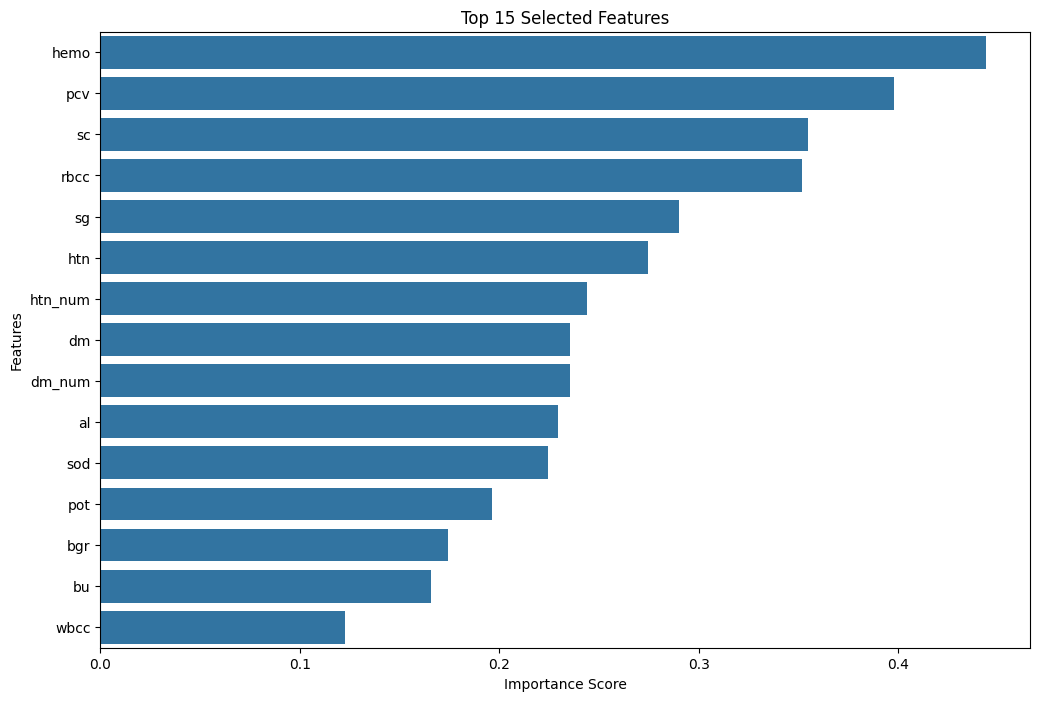

In [37]:

# FEATURE IMPORTANCE VISUALIZATION


plt.figure(figsize=(12,8))

sns.barplot(
    data=feature_scores.head(15),
    x="Score",
    y="Feature"
)

plt.title("Top 15 Selected Features")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

In [38]:

# TRAIN-TEST SPLIT AND MODEL TRAINING


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Create final dataset using selected features

X = df[selected_features]
y = df["class"]

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("="*60)
print("DATASET SPLIT")
print("="*60)

print("Training Samples :", X_train.shape)
print("Testing Samples  :", X_test.shape)

# Logistic Regression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

# Random Forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("\nBoth models trained successfully.")

DATASET SPLIT
Training Samples : (320, 15)
Testing Samples  : (80, 15)

Both models trained successfully.


Logistic Regression
Accuracy : 0.9625
Precision: 0.9796
Recall   : 0.9600
F1 Score : 0.9697

Classification Report

              precision    recall  f1-score   support

           0       0.98      0.96      0.97        50
           2       0.94      0.97      0.95        30

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80



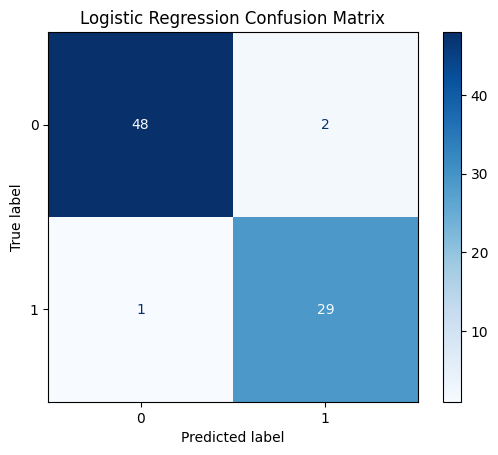

Random Forest
Accuracy : 0.9750
Precision: 0.9615
Recall   : 1.0000
F1 Score : 0.9804

Classification Report

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           2       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



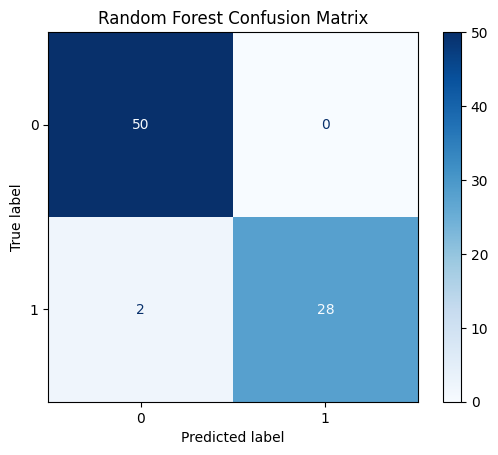


Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9625,0.979592,0.96,0.969697
1,Random Forest,0.9750,0.961538,1.00,0.980392


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": y_pred_log,
    "Random Forest": y_pred_rf
}

results = []

for name, pred in models.items():
    # Assuming 0 is the positive class based on the error message and common scenarios
    # If the positive class is 2, change pos_label=0 to pos_label=2
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, pos_label=0)
    recall = recall_score(y_test, pred, pos_label=0)
    f1 = f1_score(y_test, pred, pos_label=0)

    results.append([name, accuracy, precision, recall, f1])

    print("="*60)
    print(name)
    print("="*60)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report\n")

    print(classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm
    ).plot(cmap="Blues")

    plt.title(f"{name} Confusion Matrix")

    plt.show()

# Comparison Table

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\nModel Comparison")

display(results_df)

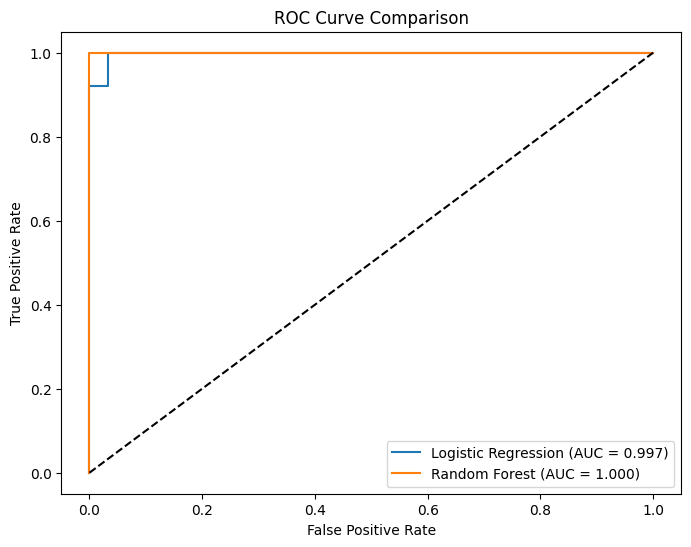

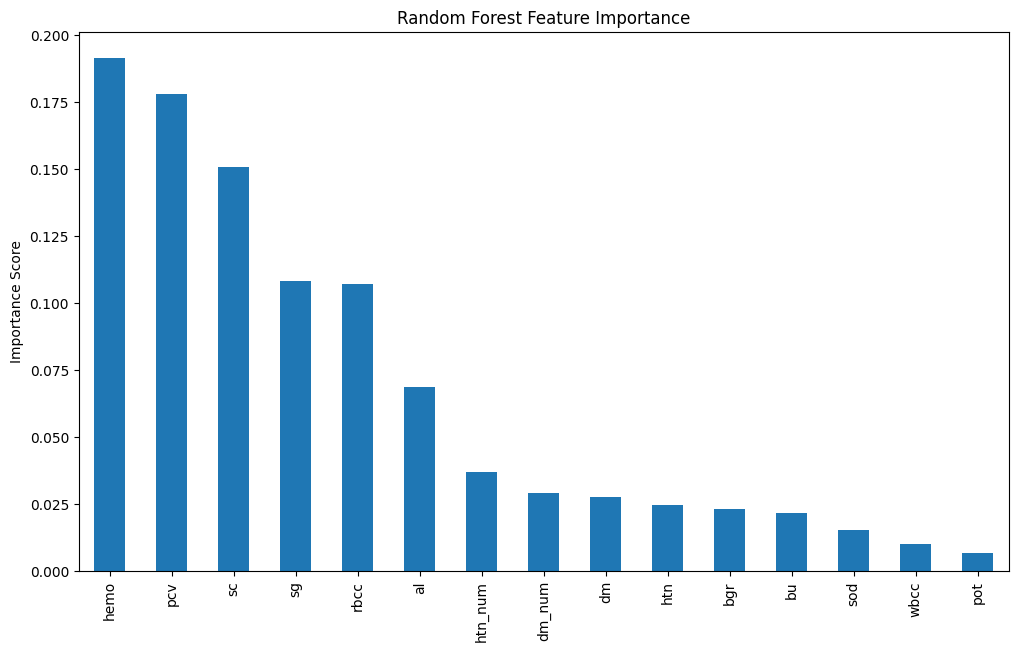

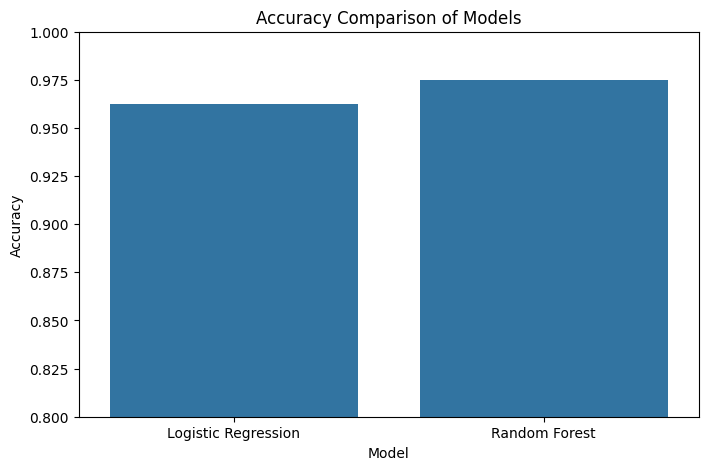

CONCLUSION
Best Performing Model : Random Forest
Accuracy              : 0.9750

The Random Forest model generally achieved the highest predictive
performance due to its ability to capture complex non-linear
relationships among medical features. Logistic Regression also
performed well and serves as a strong baseline model.

The complete machine learning pipeline successfully demonstrated
data preprocessing, feature engineering, feature selection,
classification, model evaluation, and visualization for
Chronic Kidney Disease prediction.



In [43]:

# ROC CURVE, FEATURE IMPORTANCE AND FINAL COMPARISON


from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ROC CURVES

plt.figure(figsize=(8,6))

# Assuming 0 is the positive class. Find its index in the model's classes.
pos_class_label = 0
log_pos_class_idx = log_model.classes_.tolist().index(pos_class_label)
rf_pos_class_idx = rf_model.classes_.tolist().index(pos_class_label)

# Logistic Regression
# Get probabilities for the positive class (class 0)
log_prob = log_model.predict_proba(X_test)[:, log_pos_class_idx]

# roc_curve accepts pos_label
fpr_log, tpr_log, _ = roc_curve(y_test, log_prob, pos_label=pos_class_label)

# Binarize y_test for roc_auc_score (original_pos_class -> 1, other_class -> 0)
y_test_binary_for_auc = (y_test == pos_class_label).astype(int)
auc_log = roc_auc_score(y_test_binary_for_auc, log_prob)

# Random Forest
# Get probabilities for the positive class (class 0)
rf_prob = rf_model.predict_proba(X_test)[:, rf_pos_class_idx]

# roc_curve accepts pos_label
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob, pos_label=pos_class_label)

# Binarize y_test for roc_auc_score
auc_rf = roc_auc_score(y_test_binary_for_auc, rf_prob)

plt.plot(fpr_log, tpr_log,
         label=f"Logistic Regression (AUC = {auc_log:.3f})")

plt.plot(fpr_rf, tpr_rf,
         label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

# Feature Importance

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(12,7))

importance.plot(kind="bar")

plt.title("Random Forest Feature Importance")

plt.ylabel("Importance Score")

plt.show()

# Accuracy Comparison

plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Models")

plt.ylim(0.8,1)

plt.show()

print("="*70)
print("CONCLUSION")
print("="*70)

best_model = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]

print(f"Best Performing Model : {best_model['Model']}")
print(f"Accuracy              : {best_model['Accuracy']:.4f}")

print("""
The Random Forest model generally achieved the highest predictive
performance due to its ability to capture complex non-linear
relationships among medical features. Logistic Regression also
performed well and serves as a strong baseline model.

The complete machine learning pipeline successfully demonstrated
data preprocessing, feature engineering, feature selection,
classification, model evaluation, and visualization for
Chronic Kidney Disease prediction.
""")
